In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from matplotlib import pyplot
import os

import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

2023-11-21 11:51:11.416455: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [3]:
def get_max_class(nsrc_df, classes):
    ind_max = np.argmax(nsrc_df['n'].loc[classes])
    return classes[ind_max]

def get_nsrc(nsrc_df, classes):
    return np.sum(nsrc_df['n'].loc[classes])

In [4]:
save_plots = 1
save_png = 0
copy2tex = 0


In [5]:
script_fn = 'fermi_multiclass/notebooks/tf_test.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

# select the catalog and the case
cat_name = '4FGL-DR3' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    #baseline_case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_GMM_RF_w'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'
    baseline_case = '4FGL-DR4_GMM_RF_no_coord'
    case = '4FGL-DR4_GMM_RF_no_coord'
if cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp_nmin50'


baseline = (case == baseline_case)
root_folder = '../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')

alg = cdict.get('class_alg', 'RF')
train_weighting = cdict.get('train_weighting')
test_weighting = cdict.get('test_weighting')
weighted = (train_weighting is not None) or (test_weighting is not None)
#oversample_factor = 1 # used for 'resampled' training and testing
max_sample = int(cdict.get('max_sample', 7))
test_frac = float(cdict.get('test_frac', 0.3))
nav = int(cdict.get('nav', 10))


tree_alg = cdict.get('sep_model', 'GMM')
#tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', '2class', 'RF_aakash'


# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
cat_tree = list(tree_cat_dict.keys())
nclasses = len(tree_cat_dict)

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)
assoc_classes = list(nsrc_dict.keys())




horiz_trees = util.get_horiz_trees(cat_tree, mode='add_0')
subtree  = horiz_trees[-1]
cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict, 
                                              include_parents=True)
#nodes = subtree
class_dict = {subtree[i]:i for i in range(len(subtree))}
class_dict_inv = {i:subtree[i] for i in range(len(subtree))}


plots_folder = '../plots/mclass/NN_TF_test_%s/' % cat_name
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/'

putil.setup_figure_pars()
print(features)

['log10(Energy_Flux100)', 'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV', 'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)']


In [6]:
tree_cat_dict

{'0000': ['gc', 'snr', 'pwn'],
 '0001': ['glc', 'lmb', 'msp', 'bin'],
 '001': ['sfr', 'agn', 'hmb', 'sey', 'nov', 'psr', 'gal', 'nlsy1'],
 '010': ['ssrq', 'fsrq', 'rdg'],
 '011': ['sbg', 'css', 'bll']}

In [7]:
print(tree_cat_fn)

../data_out//tree_cat_4FGL-DR3_sep_model_GMM_nmin_50_no_bcu_spp_no_coord_features.yaml


In [8]:
if weighted:
    print('Weighted')
    weights_fn = util.get_weights_fn(cdict)
    weights_df = pd.read_csv(weights_fn, index_col=0)
    sample_ratio = util.get_sample_ratio(weights_df['unas_pdf'], weights_df['assoc_pdf'], binary=False, 
                                         max_sample=max_sample)
    print(weights_df)
else:
    print('Not weighted')

Not weighted


In [9]:
horiz_trees

[['00', '01'],
 ['000', '001', '010', '011'],
 ['0000', '0001', '0010', '0100', '0110']]

In [10]:
class_dict

{'0000': 0, '0001': 1, '0010': 2, '0100': 3, '0110': 4}

In [11]:
# data preparation
ys = np.zeros(ns, dtype='<U6')
#if level == level0:
#    ys_true = ys
clf_mask = np.zeros(ns, dtype=bool)
#cls_masks_all = []
for key, cls in cut_subtree.items():
    cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)
    #cls_masks_all.append(cls_mask)
    ys[cls_mask] = key
    clf_mask[cls_mask] = True
#cls_masks_all = np.array(cls_masks_all)

X = xdf[features][clf_mask]
y_class = ys[clf_mask]
y = np.array([class_dict[cl] for cl in y_class])
#y = pd.get_dummies(y_class, dtype=int).values
#y = y_class
clf_inds = np.arange(len(xdf))[clf_mask]

#test_frac = 0.7
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_frac, random_state=0)


In [12]:
# plot ROC AUC for different numbers of epochs and different classes
test_frac = 0.3
#X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=test_frac, random_state=1)
seed = 1
rstate = np.random.RandomState(seed=seed)
test_inds = rstate.choice(clf_inds, size=int(len(clf_inds) * test_frac), replace=False, p=None)
train_inds = [i for i in clf_inds if i not in test_inds]
if weighted:
    sample_ratio_train = sample_ratio.iloc[train_inds]
    sample_ratio_test = sample_ratio.iloc[test_inds]
else:
    sample_ratio_train = None
    sample_ratio_test = None
    
X_train = xdf[features].iloc[train_inds]
X_test = xdf[features].iloc[test_inds]
y_train = ys[train_inds]
y_test = ys[test_inds]



nepochs_step = 50
nepochs_total = 2000
par_dict = util.pars_dict['NN']
par_dict['nfeatures'] = len(features)
par_dict['classes'] = subtree
par_dict['epochs'] = nepochs_step
par_dict['verbose'] = 0

if 0:
    par_dict = {'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': nepochs_step, 'activation': 'tanh', 
               'hidden_layer_sizes': [20, 10], 
               'nfeatures': len(features), 'classes': subtree, 'verbose': 0,
               'drop_rate': 0.0, 'batch_size': 200,
              'validation_split': None}

clf = util.NNClassifierTF(**par_dict)
npoints = int(nepochs_total / nepochs_step)
nclasses = len(subtree)
auc_scan = np.zeros((nclasses, npoints))
acc_scan = np.zeros(npoints)
epochs = nepochs_step * np.arange(1, npoints + 1)
for i in range(npoints):
    print('%i of %i' % (i + 1, npoints))
    clf.fit(X_train, y_train, sample_weight=sample_ratio_train)
    y_pred = clf.predict_proba(X_test).T
    for ind in range(nclasses):
        y_score = y_pred[ind]
        y_true = (y_test == clf.classes_[ind])
        auc_scan[ind][i] = roc_auc_score(y_true, y_score, sample_weight=sample_ratio_test)
        acc_scan[i] = clf.test_accuracy(X_test, y_test, sample_weight=sample_ratio_test)
    print(auc_scan[:, i], acc_scan[i])

2023-11-21 11:51:17.509006: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


1 of 40
[0.56721657 0.94622159 0.90901319 0.91731698 0.93506318] 0.8128019571304321
2 of 40
[0.61688312 0.96391237 0.92690277 0.93032085 0.94331583] 0.8182367086410522
3 of 40
[0.69269919 0.96463804 0.92805694 0.93361919 0.94496284] 0.8216586112976074
4 of 40
[0.75640576 0.96455959 0.92504328 0.93469992 0.94546691] 0.820652186870575
5 of 40
[0.78562654 0.96565791 0.93158356 0.93498765 0.94779382] 0.8212560415267944
6 of 40
[0.80572131 0.9660894  0.93081412 0.93511397 0.9488723 ] 0.8226650357246399
7 of 40
[0.81484731 0.96710926 0.93250262 0.9359561  0.95070687] 0.8226363062858582
8 of 40
[0.82406107 0.96648165 0.93188279 0.93542275 0.95053103] 0.8227657079696655
9 of 40
[0.82660583 0.96785455 0.93036527 0.93620172 0.95112302] 0.8232689499855042
10 of 40
[0.83590734 0.96744268 0.93087824 0.93600522 0.95109957] 0.823913037776947
11 of 40
[0.84354159 0.96865868 0.93064313 0.93621575 0.95179706] 0.8245498538017273
12 of 40
[0.8493331  0.96795262 0.93006604 0.93606136 0.95205496] 0.82457727

save figure to file: ../plots/mclass/NN_TF_test_4FGL-DR3//NN_TF_epochs_test_4FGL-DR3_GMM_RF_no_coord_no_bcu_spp_nmin50.pdf


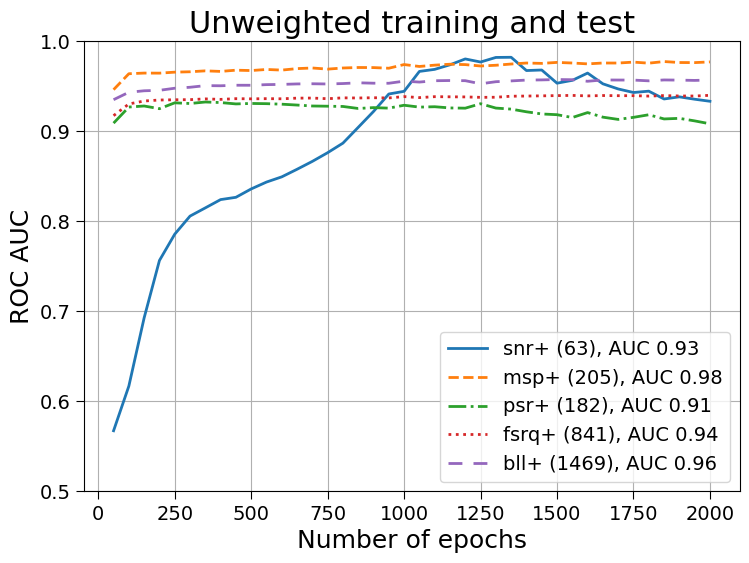

In [13]:
lss = ['-', '--', '-.', ':', (0, (5, 4)), (0, (4, 5, 1, 5))]

pyplot.figure()
#pyplot.plot(epochs, acc_scan, linestyle=lss[0], lw=2., label='Accuracy')
for ind in range(nclasses):
    classes = cut_subtree[subtree[ind]]
    mclass = get_max_class(nsrc_df, classes)
    nsrc = get_nsrc(nsrc_df, classes)
    pyplot.plot(epochs, auc_scan[ind], linestyle=lss[ind], lw=2.,
                label='%s+ (%i), AUC %.2f' % (mclass, nsrc, auc_scan[ind][-1]))
pyplot.legend(loc='lower right', ncol=1)
pyplot.grid()
if weighted:
    vmin = 0.4
else:
    vmin = 0.5
pyplot.ylim(vmin, 1.0)
pyplot.xlabel('Number of epochs')
pyplot.ylabel('ROC AUC')
if weighted:
    pyplot.title('Weighted training and test')
else:
    pyplot.title('Unweighted training and test')
#ax.text(xtext_pos, 0.1, text, #fontsize=12, horizontalalignment='right', verticalalignment='bottom')

if save_plots:
    fn = '%s/NN_TF_epochs_test_%s.pdf' % (plots_folder, case)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [14]:
#save_plots = 0

In [15]:
if 0:
    par_dict['epochs'] = 1000
    clf = util.NNClassifierTF(**par_dict)
    clf.fit(X_train, y_train)


In [16]:
auc_final = np.zeros(nclasses)
y_pred = clf.predict_proba(X_test).T
for ind in range(nclasses):
    y_score = y_pred[ind]
    y_true = (y_test == clf.classes_[ind])
    auc_final[ind] = roc_auc_score(y_true, y_score)

In [17]:
auc_final

array([0.93330993, 0.97705297, 0.90828649, 0.9399141 , 0.95690807])

In [18]:
auc_scan[:, -1]

array([0.93330993, 0.97705297, 0.90828649, 0.9399141 , 0.95690807])

In [19]:
cut_subtree

{'0000': ['gc', 'snr', 'pwn'],
 '0001': ['glc', 'lmb', 'msp', 'bin'],
 '0010': ['sfr', 'agn', 'hmb', 'sey', 'nov', 'psr', 'gal', 'nlsy1'],
 '0100': ['ssrq', 'fsrq', 'rdg'],
 '0110': ['sbg', 'css', 'bll']}